# Series de tiempo: pronóstico semanal de WTI y Brent
## Período 2 · Suavizamiento exponencial de Holt con tendencia amortiguada

Se ajusta un modelo independiente para cada crudo usando **solo cotizaciones desde el 01/04/2026**, el período asociado al contexto de guerra en el diseño del TP.

El objetivo es pronosticar los precios diarios en USD por barril de **lunes a viernes de la semana siguiente a la fecha de ejecución en Argentina**. La semana se recalcula al ejecutar todas las celdas. No se programa una ejecución automática.

“Series de tiempo” es una familia de métodos que también incluye ARIMA. Para contar con dos enfoques distintos en el TP, este archivo desarrolla **Holt**; ARIMA se trabajará por separado. Holt estima el nivel y una tendencia que pierde fuerza al extenderse el horizonte. Se compara con mantener el último precio conocido, sin suponer que el método más elaborado necesariamente será mejor.

Las cotizaciones, las predicciones y los errores de validación se presentan por separado: los valores futuros todavía no son observaciones reales.

In [1]:
from pathlib import Path
import platform

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import statsmodels
from IPython.display import Markdown, display
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.holtwinters import Holt

plt.style.use("seaborn-v0_8-whitegrid")
COLORES = {"WTI": "#2864A0", "Brent": "#D08023"}

## 1. Configuración de la próxima semana

La opción inicial consulta **EIA** en cada ejecución y aplica los criterios de limpieza del notebook del período 2. Se requiere la clave local ya utilizada en el proyecto. Para trabajar sin conexión se puede cambiar `FUENTE_DATOS` a `"CSV"`; en ese caso se usa la copia de `data/` cuyo nombre tiene el mes más reciente y se informa su fecha de corte.

`FECHA_REFERENCIA = None` utiliza el día actual de Argentina. Para reproducir un corte pasado se puede indicar una fecha como `"2026-10-20"`: se excluyen las cotizaciones posteriores, aunque la fuente consultada hoy puede contener revisiones históricas. El notebook no sobrescribe los CSV.

Los cinco días futuros son una **referencia de lunes a viernes**, no un calendario oficial de publicación de cada crudo. Si una fecha no tiene cotización real, no se debe inventar un precio para evaluarla.

In [2]:
PROJECT_ROOT = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / "requirements.txt").is_file() and (p / "notebooks").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("No se encontró la raíz del proyecto.")

FUENTE_DATOS = "EIA"       # Alternativa sin conexión: "CSV"
FECHA_REFERENCIA = None    # None = hoy en Argentina; o una fecha "AAAA-MM-DD"
ZONA_HORARIA = "America/Argentina/Buenos_Aires"
INICIO_PERIODO_2 = pd.Timestamp("2026-04-01")
N_ORIGENES_VALIDACION = 3
N_SIMULACIONES = 3000
SEMILLA = 42

fecha_referencia = (
    pd.Timestamp.now(tz=ZONA_HORARIA).tz_localize(None).normalize()
    if FECHA_REFERENCIA is None else pd.Timestamp(FECHA_REFERENCIA).normalize()
)
inicio_semana = fecha_referencia + pd.Timedelta(days=7 - fecha_referencia.weekday())
fin_semana = inicio_semana + pd.Timedelta(days=4)
fechas_objetivo = pd.bdate_range(inicio_semana, fin_semana)
if fecha_referencia < INICIO_PERIODO_2:
    raise ValueError("La fecha de referencia debe pertenecer al período 2.")

display(Markdown(
    f"**Fecha de referencia (Argentina):** {fecha_referencia:%d/%m/%Y}.  \n"
    f"**Semana a pronosticar:** {inicio_semana:%d/%m/%Y} a {fin_semana:%d/%m/%Y}.  \n"
    f"**Fuente seleccionada:** {FUENTE_DATOS}."
))

**Fecha de referencia (Argentina):** 20/10/2026.  
**Semana a pronosticar:** 26/10/2026 a 30/10/2026.  
**Fuente seleccionada:** EIA.

## 2. Obtención de los datos

Se consultan los precios spot diarios de EIA para WTI y Brent. La consulta se limita al período 2 y a la fecha de referencia; la fecha de corte real depende de la última publicación recibida. El modelo trabaja con los precios de cada crudo por separado.

In [3]:
if FUENTE_DATOS == "EIA":
    key_path = PROJECT_ROOT / "secret_api_key.txt"
    if not key_path.is_file():
        raise FileNotFoundError(
            "Falta secret_api_key.txt. Configurar la clave de EIA o seleccionar FUENTE_DATOS = 'CSV'."
        )
    api_key = key_path.read_text(encoding="utf-8").strip()
    if not api_key:
        raise ValueError("La clave de EIA está vacía.")
    parametros = {
        "api_key": api_key,
        "frequency": "daily",
        "data[0]": "value",
        "facets[product][]": ["EPCWTI", "EPCBRENT"],
        "start": INICIO_PERIODO_2.strftime("%Y-%m-%d"),
        "end": fecha_referencia.strftime("%Y-%m-%d"),
        "sort[0][column]": "period",
        "sort[0][direction]": "asc",
        "offset": 0,
        "length": 5000,
    }
    try:
        respuesta = requests.get(
            "https://api.eia.gov/v2/petroleum/pri/spt/data/",
            params=parametros,
            timeout=60,
        )
        respuesta.raise_for_status()
    except requests.RequestException as error:
        estado = getattr(error.response, "status_code", "sin respuesta")
        raise RuntimeError(
            f"No se pudo consultar EIA (HTTP: {estado}). "
            "Revisar la conexión o seleccionar FUENTE_DATOS = 'CSV'."
        ) from None
    try:
        contenido = respuesta.json()["response"]
        registros = contenido["data"]
    except (ValueError, KeyError, TypeError):
        raise RuntimeError("EIA no devolvió la estructura de datos esperada.") from None
    if int(contenido.get("total", len(registros))) > len(registros):
        raise ValueError("La respuesta de EIA está incompleta; se necesita paginación.")
    datos_originales = pd.DataFrame(registros)
    origen = "API EIA · precios spot diarios"
    del api_key, parametros, respuesta
elif FUENTE_DATOS == "CSV":
    archivos = sorted((PROJECT_ROOT / "data").glob("eia_precios_crudo_diarios_*.csv"))
    if not archivos:
        raise FileNotFoundError("No se encontró un CSV local de precios diarios.")
    csv_path = archivos[-1]
    # El texto literal 'NA' de area_name no se interpreta como un dato faltante.
    datos_originales = pd.read_csv(csv_path, keep_default_na=False)
    origen = f"CSV local · {csv_path.name}"
else:
    raise ValueError("FUENTE_DATOS debe ser 'EIA' o 'CSV'.")

print(f"Origen: {origen}")
print(f"Filas recibidas: {len(datos_originales):,}")

Origen: API EIA · precios spot diarios
Filas recibidas: 274


## 3. Limpieza y validación

Se mantiene la lógica ya utilizada en `periodo_2_wti_brent.ipynb`: se conserva la tabla original, se normalizan los textos, se convierten fechas y precios, y se eliminan duplicados completos. Los duplicados por fecha y crudo, los nulos y los precios no finitos detienen el ajuste.

Para la fuente CSV, primero se selecciona el período 2 hasta el corte indicado. **Ningún precio de otro período entra en el ajuste, las ventanas móviles o la validación.** No se rellenan fines de semana, feriados ni cotizaciones ausentes.

In [4]:
df_periodo_2_limpio = datos_originales.copy()
df_periodo_2_limpio.columns = df_periodo_2_limpio.columns.str.replace("_", "-", regex=False)
requeridas = {"period", "series", "value"}
if not requeridas.issubset(df_periodo_2_limpio.columns):
    raise ValueError("Faltan columnas de fecha, serie o precio.")

for columna in df_periodo_2_limpio.columns.difference(["period", "value"]):
    df_periodo_2_limpio[columna] = (
        df_periodo_2_limpio[columna].astype("string").str.strip().replace("", pd.NA)
    )
df_periodo_2_limpio["period"] = pd.to_datetime(
    df_periodo_2_limpio["period"], errors="coerce"
)
df_periodo_2_limpio["value"] = pd.to_numeric(
    df_periodo_2_limpio["value"], errors="coerce"
)
if df_periodo_2_limpio["period"].isna().any():
    raise ValueError("Hay fechas inválidas en la fuente.")

en_periodo = df_periodo_2_limpio["period"].between(INICIO_PERIODO_2, fecha_referencia)
filas_excluidas = int((~en_periodo).sum())
df_periodo_2_limpio = df_periodo_2_limpio.loc[en_periodo].copy()
duplicados_eliminados = int(df_periodo_2_limpio.duplicated().sum())
df_periodo_2_limpio = df_periodo_2_limpio.drop_duplicates().reset_index(drop=True)
if df_periodo_2_limpio.empty:
    raise ValueError("No hay datos para el período 2 hasta la fecha de referencia.")
if not df_periodo_2_limpio["series"].isin(["RWTC", "RBRTE"]).all():
    raise ValueError("La fuente contiene una serie distinta de WTI o Brent.")

textos = df_periodo_2_limpio.select_dtypes(include=["object", "string"])
validacion_limpieza = pd.DataFrame({
    "Control": [
        "Nulos", "Cadenas vacías", "Valores con solo espacios",
        "Duplicados completos", "Duplicados por fecha y serie",
    ],
    "Cantidad": [
        int(df_periodo_2_limpio.isna().sum().sum()),
        int(textos.eq("").sum().sum()),
        sum(int(textos[c].str.fullmatch(r"\s+", na=False).sum()) for c in textos),
        int(df_periodo_2_limpio.duplicated().sum()),
        int(df_periodo_2_limpio.duplicated(["period", "series"]).sum()),
    ],
})
validacion_limpieza["Estado"] = np.where(validacion_limpieza["Cantidad"].eq(0), "OK", "REVISAR")
display(validacion_limpieza)
print(f"Filas excluidas por estar fuera del período/corte: {filas_excluidas}")
print(f"Duplicados completos eliminados: {duplicados_eliminados}")
if not validacion_limpieza["Cantidad"].eq(0).all():
    raise ValueError("Resolver los problemas de limpieza antes de ajustar.")
if not np.isfinite(df_periodo_2_limpio["value"]).all():
    raise ValueError("Hay precios no finitos.")

,Control,Cantidad,Estado
0,Nulos,0,OK
1,Cadenas vacías,0,OK
2,Valores con solo espacios,0,OK
3,Duplicados completos,0,OK
4,Duplicados por fecha y serie,0,OK


Filas excluidas por estar fuera del período/corte: 0
Duplicados completos eliminados: 0


## 4. Series y horizonte real del pronóstico

Cada serie conserva sus propias fechas y cotizaciones válidas. Para ajustar Holt se utilizan observaciones consecutivas: un paso equivale a la siguiente cotización disponible, aunque entre dos precios puedan transcurrir varios días calendario.

Para colocar los pronósticos futuros se supone una cotización por día de lunes a viernes. Se informa todo el recorrido desde el último precio hasta el viernes objetivo. **Pronosticar una semana concreta puede requerir más de cinco pasos** si faltan publicaciones recientes. Esta aproximación de calendario se debe revisar al comparar luego con precios reales.

,Crudo,Primera cotización,Última cotización,Cotizaciones,Demora al corte (días calendario),Pasos totales,Pasos de la semana objetivo
0,WTI,2026-04-01,2026-10-14,138,6,12,8 a 12
1,Brent,2026-04-01,2026-10-14,136,6,12,8 a 12


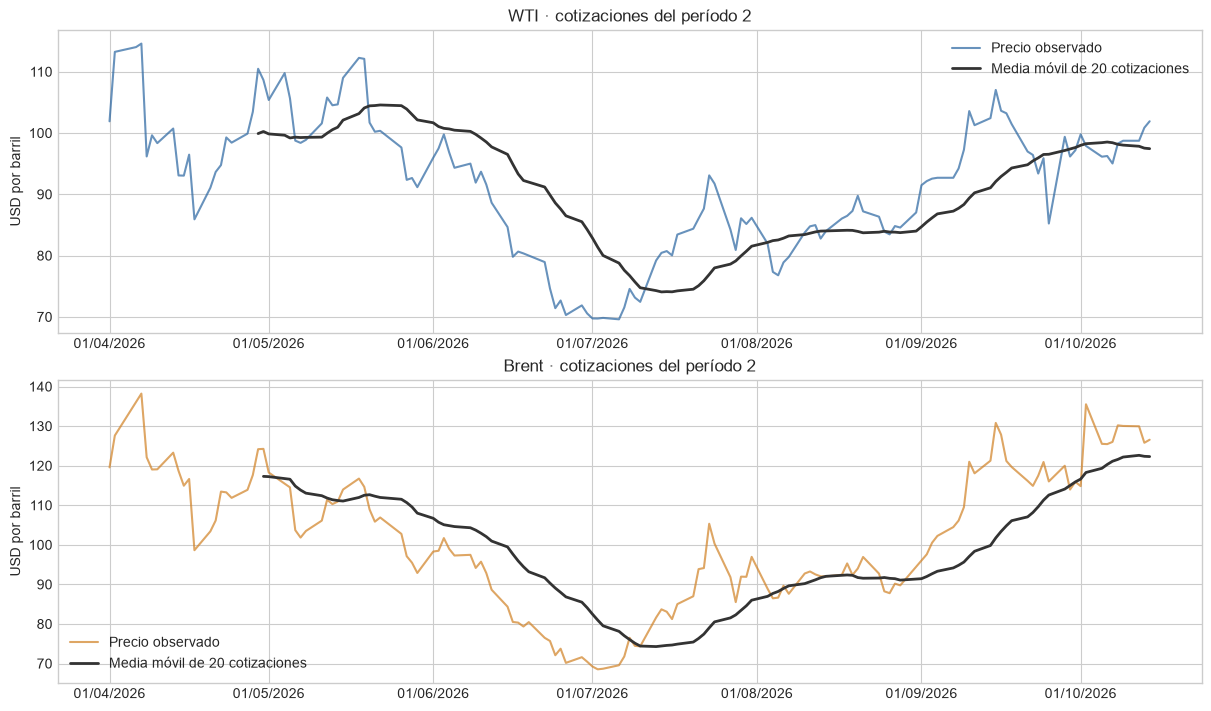

La media móvil ayuda a leer la evolución histórica; el pronóstico se obtiene con Holt. Las 20 observaciones de la ventana no equivalen a 20 días calendario.

In [5]:
series_periodo_2 = {}
fechas_futuras = {}
horizontes = {}
filas_cobertura = []
for crudo, codigo in {"WTI": "RWTC", "Brent": "RBRTE"}.items():
    muestra = df_periodo_2_limpio.loc[
        df_periodo_2_limpio["series"].eq(codigo), ["period", "value"]
    ].sort_values("period")
    serie = muestra.set_index("period")["value"].astype(float).rename(crudo)
    if len(serie) < 40:
        raise ValueError(f"{crudo}: se requieren al menos 40 cotizaciones.")
    if serie.index.max() >= inicio_semana:
        raise ValueError("Hay datos de la semana objetivo dentro del entrenamiento.")
    futuro = pd.bdate_range(serie.index.max() + pd.Timedelta(days=1), fin_semana)
    if not fechas_objetivo.isin(futuro).all():
        raise ValueError("El calendario futuro no incluye toda la semana objetivo.")
    series_periodo_2[crudo] = serie
    fechas_futuras[crudo] = futuro
    horizontes[crudo] = len(futuro)
    posiciones_objetivo = np.flatnonzero(futuro.isin(fechas_objetivo)) + 1
    filas_cobertura.append({
        "Crudo": crudo,
        "Primera cotización": serie.index.min().date(),
        "Última cotización": serie.index.max().date(),
        "Cotizaciones": len(serie),
        "Demora al corte (días calendario)": (fecha_referencia - serie.index.max()).days,
        "Pasos totales": len(futuro),
        "Pasos de la semana objetivo": f"{posiciones_objetivo[0]} a {posiciones_objetivo[-1]}",
    })
cobertura = pd.DataFrame(filas_cobertura)
display(cobertura)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
for ax, (crudo, serie) in zip(axes, series_periodo_2.items()):
    ax.plot(serie.index, serie, color=COLORES[crudo], alpha=0.7, label="Precio observado")
    ax.plot(serie.index, serie.rolling(20, min_periods=20).mean(),
            color="#333333", linewidth=2, label="Media móvil de 20 cotizaciones")
    ax.set(title=f"{crudo} · cotizaciones del período 2", ylabel="USD por barril")
    ax.legend(loc="best")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%Y"))
plt.show()
display(Markdown(
    "La media móvil ayuda a leer la evolución histórica; el pronóstico se obtiene con Holt. "
    "Las 20 observaciones de la ventana no equivalen a 20 días calendario."
))

## 5. Modelo clásico: Holt con tendencia amortiguada

El método actualiza dos componentes: el **nivel** (precio suavizado) y la **tendencia** (cambio estimado por cotización). Los parámetros se estiman con los datos disponibles en cada entrenamiento.

\[
\ell_t=\alpha y_t+(1-\alpha)(\ell_{t-1}+\phi b_{t-1})
\]
\[
b_t=\beta(\ell_t-\ell_{t-1})+(1-\beta)\phi b_{t-1}
\]
\[
\hat y_{T+h\mid T}=\ell_T+(\phi+\phi^2+\cdots+\phi^h)b_T
\]

Aquí \(\alpha\) y \(\beta\) controlan las actualizaciones, y \(\phi\) amortigua la tendencia. Se usa una forma aditiva sobre los precios, sin componente estacional. No requiere diferenciar previamente la serie. La elección es un punto de comparación académico; su precisión se evalúa con datos posteriores al entrenamiento.

Referencia del método: [Hyndman y Athanasopoulos, métodos con tendencia](https://otexts.com/fpp3/holt.html). Implementación: [statsmodels, suavizamiento exponencial](https://www.statsmodels.org/stable/examples/notebooks/generated/exponential_smoothing.html).

In [6]:
def ajustar_holt(serie):
    """Ajuste separado, con valores ordenados y sin usar fechas futuras."""
    valores = np.asarray(serie, dtype=float)
    if len(valores) < 40 or not np.isfinite(valores).all():
        raise ValueError("El entrenamiento necesita 40 precios válidos como mínimo.")
    ajuste = Holt(
        valores,
        exponential=False,
        damped_trend=True,
        initialization_method="estimated",
    ).fit(optimized=True)
    if not ajuste.mle_retvals.get("success", True):
        raise RuntimeError("El ajuste de Holt no convergió.")
    return ajuste


def calcular_metricas(real, predicho):
    error = np.asarray(real, dtype=float) - np.asarray(predicho, dtype=float)
    return {
        "MAE (USD/barril)": float(np.mean(np.abs(error))),
        "RMSE (USD/barril)": float(np.sqrt(np.mean(error ** 2))),
    }

## 6. Validación temporal frente al último precio

Se utilizan **tres cortes históricos** que avanzan de a cinco cotizaciones, todos dentro del período 2. En cada corte:

1. Se ajusta Holt únicamente con el pasado.
2. Se pronostica el mismo número de pasos que exige hoy llegar al viernes objetivo.
3. Se evalúan los últimos cinco pasos de ese recorrido. Las tres ventanas evaluadas no se superponen.
4. Se compara con el método ingenuo: repetir el último precio del entrenamiento.

Así se respeta el intervalo previo a la semana objetivo, en lugar de evaluar solo cinco pasos cuando el pronóstico real exige más. Los pasos históricos cuentan cotizaciones, por lo que su duración calendario puede variar. **MAE** mide el error absoluto promedio y **RMSE** da mayor peso a errores grandes; cuanto menores, mejor. Se mantienen fijos el tipo de modelo y este diseño: la validación no se utiliza para elegir parámetros manualmente.

Referencia: [evaluación temporal de pronósticos](https://otexts.com/fpp3/tscv.html).

In [7]:
filas_errores = []
filas_ventanas = []
ultimas_validaciones = {}
for crudo, serie in series_periodo_2.items():
    h = horizontes[crudo]
    primer_origen = len(serie) - h - (N_ORIGENES_VALIDACION - 1) * 5
    if primer_origen < 40:
        raise ValueError(
            f"{crudo}: faltan datos para validar un horizonte de {h} pasos. "
            "Actualizar la fuente o revisar la fecha de referencia."
        )
    for numero in range(N_ORIGENES_VALIDACION):
        origen_idx = primer_origen + numero * 5
        entrenamiento = serie.iloc[:origen_idx]
        observado = serie.iloc[origen_idx:origen_idx + h]
        ajuste = ajustar_holt(entrenamiento)
        pred_holt = np.asarray(ajuste.forecast(h), dtype=float)
        pred_ingenuo = np.repeat(entrenamiento.iloc[-1], h)
        evaluado = observado.iloc[-5:]
        filas_ventanas.append({
            "Crudo": crudo, "Corte": numero + 1, "n entrenamiento": len(entrenamiento),
            "Último dato entrenado": entrenamiento.index[-1].date(),
            "Evaluación desde": evaluado.index[0].date(),
            "Evaluación hasta": evaluado.index[-1].date(),
            "Pasos totales": h, "Pasos evaluados": 5,
        })
        for modelo, predicciones in [("Holt amortiguado", pred_holt), ("Último precio", pred_ingenuo)]:
            for fecha, real, predicho in zip(evaluado.index, evaluado, predicciones[-5:]):
                filas_errores.append({
                    "Crudo": crudo, "Corte": numero + 1, "Modelo": modelo,
                    "Fecha": fecha, "Real": real, "Predicho": predicho,
                })
        ultimas_validaciones[crudo] = {
            "entrenamiento": entrenamiento, "observado": observado,
            "Holt": pred_holt, "Ingenuo": pred_ingenuo,
        }

ventanas_validacion = pd.DataFrame(filas_ventanas)
predicciones_validacion = pd.DataFrame(filas_errores)
filas_metricas = []
for (crudo, modelo), grupo in predicciones_validacion.groupby(["Crudo", "Modelo"], sort=False):
    if grupo["Fecha"].duplicated().any():
        raise AssertionError("Las ventanas de evaluación se superponen.")
    filas_metricas.append({
        "Crudo": crudo, "Modelo": modelo, "Predicciones evaluadas": len(grupo),
        **calcular_metricas(grupo["Real"], grupo["Predicho"]),
    })
metricas_validacion = pd.DataFrame(filas_metricas)
display(ventanas_validacion)
display(metricas_validacion.style.format({
    "MAE (USD/barril)": "{:.2f}", "RMSE (USD/barril)": "{:.2f}",
}))

,Crudo,Corte,n entrenamiento,Último dato entrenado,Evaluación desde,Evaluación hasta,Pasos totales,Pasos evaluados
0,WTI,1,116,2026-09-14,2026-09-24,2026-09-30,12,5
1,WTI,2,121,2026-09-21,2026-10-01,2026-10-07,12,5
2,WTI,3,126,2026-09-28,2026-10-08,2026-10-14,12,5
3,Brent,1,114,2026-09-14,2026-09-24,2026-09-30,12,5
4,Brent,2,119,2026-09-21,2026-10-01,2026-10-07,12,5
5,Brent,3,124,2026-09-28,2026-10-08,2026-10-14,12,5


,Crudo,Modelo,Predicciones evaluadas,MAE (USD/barril),RMSE (USD/barril)
0,WTI,Holt amortiguado,15,3.48,5.40
1,WTI,Último precio,15,3.46,5.41
2,Brent,Holt amortiguado,15,7.55,8.88
3,Brent,Último precio,15,7.42,8.72


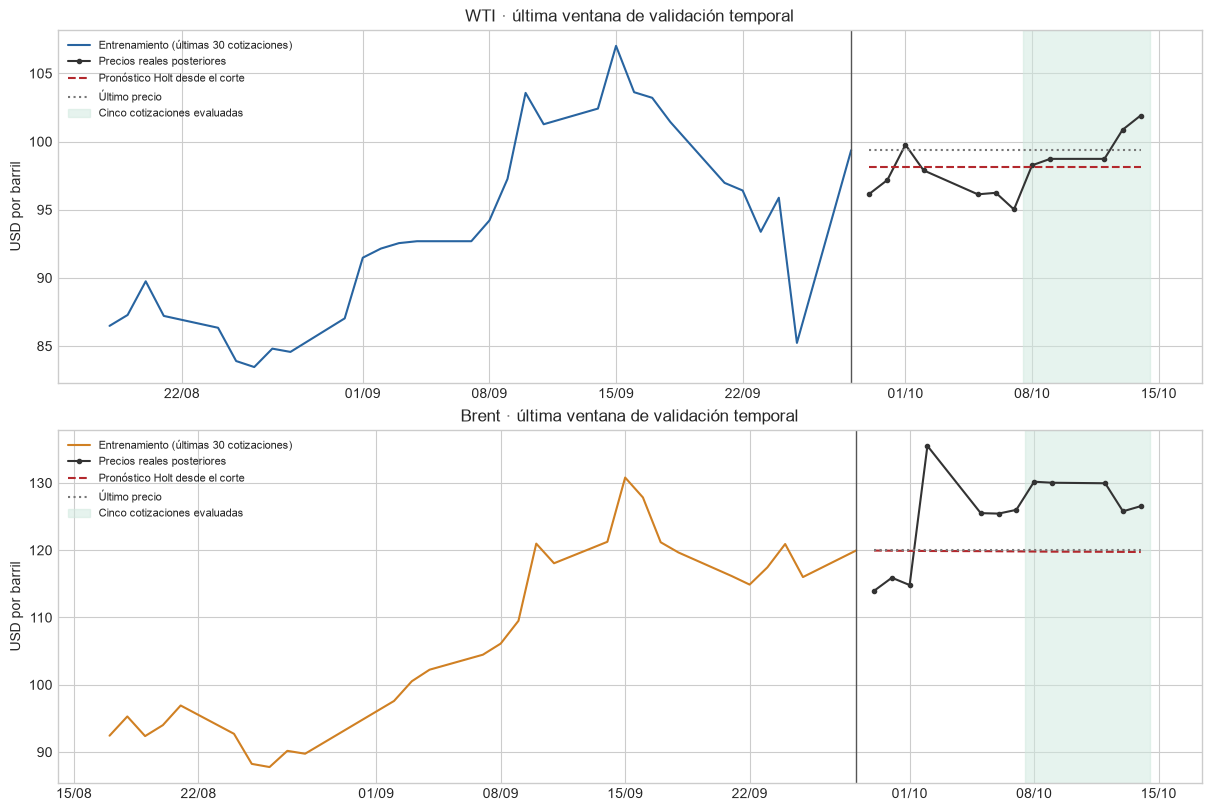

**WTI:** MAE de Holt = **3.48 USD/barril**; MAE del último precio = **3.46 USD/barril**. En estas ventanas, mantener el último precio presenta menor MAE que Holt. Son 15 cotizaciones evaluadas por método: el resultado es una evidencia acotada y no demuestra que un método será superior en todas las semanas.

**Brent:** MAE de Holt = **7.55 USD/barril**; MAE del último precio = **7.42 USD/barril**. En estas ventanas, mantener el último precio presenta menor MAE que Holt. Son 15 cotizaciones evaluadas por método: el resultado es una evidencia acotada y no demuestra que un método será superior en todas las semanas.

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)
for ax, (crudo, caso) in zip(axes, ultimas_validaciones.items()):
    entrenamiento, observado = caso["entrenamiento"], caso["observado"]
    ax.plot(entrenamiento.tail(30).index, entrenamiento.tail(30),
            color=COLORES[crudo], label="Entrenamiento (últimas 30 cotizaciones)")
    ax.plot(observado.index, observado, color="#333333", marker="o", markersize=3,
            label="Precios reales posteriores")
    ax.plot(observado.index, caso["Holt"], color="#B3282D", linestyle="--",
            label="Pronóstico Holt desde el corte")
    ax.plot(observado.index, caso["Ingenuo"], color="#777777", linestyle=":",
            label="Último precio")
    ax.axvline(entrenamiento.index[-1], color="#555555", linewidth=1)
    ax.axvspan(observado.index[-5] - pd.Timedelta(hours=12),
               observado.index[-1] + pd.Timedelta(hours=12), color="#CFE8DE", alpha=0.5,
               label="Cinco cotizaciones evaluadas")
    ax.set(title=f"{crudo} · última ventana de validación temporal", ylabel="USD por barril")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.legend(loc="best", fontsize=8)
plt.show()

for crudo in series_periodo_2:
    tabla = metricas_validacion.loc[metricas_validacion["Crudo"].eq(crudo)].set_index("Modelo")
    mae_holt = tabla.loc["Holt amortiguado", "MAE (USD/barril)"]
    mae_ingenuo = tabla.loc["Último precio", "MAE (USD/barril)"]
    if np.isclose(mae_holt, mae_ingenuo):
        lectura = "ambos métodos presentan un MAE prácticamente igual"
    elif mae_holt < mae_ingenuo:
        lectura = "Holt presenta menor MAE que mantener el último precio"
    else:
        lectura = "mantener el último precio presenta menor MAE que Holt"
    display(Markdown(
        f"**{crudo}:** MAE de Holt = **{mae_holt:.2f} USD/barril**; "
        f"MAE del último precio = **{mae_ingenuo:.2f} USD/barril**. En estas ventanas, {lectura}. "
        "Son 15 cotizaciones evaluadas por método: el resultado es una evidencia acotada "
        "y no demuestra que un método será superior en todas las semanas."
    ))

## 7. Ajuste final y pronóstico de la próxima semana

Después de medir los errores históricos se vuelve a ajustar Holt con **todo el período 2 disponible hasta el corte**. Los precios usados antes para validar ahora pertenecen al pasado conocido y pueden utilizarse en este ajuste final.

Se generan 3.000 trayectorias con errores remuestreados de los residuos centrados del ajuste. Los percentiles 2,5 y 97,5 forman una **banda de predicción aproximada del 95%**, condicionada al modelo y a los parámetros estimados. El remuestreo supone errores independientes y una variabilidad semejante a la observada; no incorpora toda la incertidumbre de parámetros ni acontecimientos nuevos. La banda no tiene una cobertura del 95% comprobada en este TP.

Documentación: [simulación de trayectorias de Holt en statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.tsa.holtwinters.HoltWintersResults.simulate.html).

In [9]:
ajustes_finales = {}
trayectorias_pronostico = {}
filas_parametros = []
for i, (crudo, serie) in enumerate(series_periodo_2.items()):
    ajuste = ajustar_holt(serie)
    ajustes_finales[crudo] = ajuste
    futuro = fechas_futuras[crudo]
    h = len(futuro)
    puntual = np.asarray(ajuste.forecast(h), dtype=float)
    residuos = np.asarray(ajuste.resid, dtype=float)
    residuos_centrados = residuos - residuos.mean()
    rng = np.random.default_rng(SEMILLA + i)
    errores = rng.choice(residuos_centrados, size=(h, N_SIMULACIONES), replace=True)
    simulaciones = np.asarray(ajuste.simulate(
        nsimulations=h, anchor="end", repetitions=N_SIMULACIONES,
        error="add", random_errors=errores,
    ))
    inferior, superior = np.quantile(simulaciones, [0.025, 0.975], axis=1)
    if not np.isfinite(puntual).all() or not np.isfinite(simulaciones).all():
        raise RuntimeError(f"{crudo}: se obtuvieron pronósticos no finitos.")
    trayectorias_pronostico[crudo] = pd.DataFrame({
        "Crudo": crudo, "Fecha": futuro, "Paso desde último dato": np.arange(1, h + 1),
        "Holt (USD/barril)": puntual, "Inferior 95% aprox.": inferior,
        "Superior 95% aprox.": superior, "Último precio (referencia)": serie.iloc[-1],
    })
    filas_parametros.append({
        "Crudo": crudo, "n": len(serie), "Alfa (nivel)": ajuste.params["smoothing_level"],
        "Beta (tendencia)": ajuste.params["smoothing_trend"],
        "Phi (amortiguación)": ajuste.params["damping_trend"],
        "Nivel final": ajuste.level[-1], "Tendencia final por cotización": ajuste.trend[-1],
    })

parametros_finales = pd.DataFrame(filas_parametros)
pronostico_completo = pd.concat(trayectorias_pronostico.values(), ignore_index=True)
pronostico_semana = pronostico_completo.loc[
    pronostico_completo["Fecha"].isin(fechas_objetivo)
].reset_index(drop=True)
if not pronostico_semana.groupby("Crudo").size().eq(5).all():
    raise AssertionError("Se esperaban cinco fechas objetivo por crudo.")
display(parametros_finales.style.format(precision=4))
display(Markdown(
    f"### Semana del {inicio_semana:%d/%m/%Y} al {fin_semana:%d/%m/%Y}\n"
    "Todos los precios y límites de la tabla se expresan en USD por barril."
))
display(pronostico_semana.style.format({
    "Fecha": lambda fecha: fecha.strftime("%d/%m/%Y"),
    "Holt (USD/barril)": "{:.2f}", "Inferior 95% aprox.": "{:.2f}",
    "Superior 95% aprox.": "{:.2f}", "Último precio (referencia)": "{:.2f}",
}))

,Crudo,n,Alfa (nivel),Beta (tendencia),Phi (amortiguación),Nivel final,Tendencia final por cotización
0,WTI,138,0.8824,0.0000,0.9758,101.7552,-0.0129
1,Brent,136,0.9365,0.0000,0.9707,126.5170,-0.0145


### Semana del 26/10/2026 al 30/10/2026
Todos los precios y límites de la tabla se expresan en USD por barril.

,Crudo,Fecha,Paso desde último dato,Holt (USD/barril),Inferior 95% aprox.,Superior 95% aprox.,Último precio (referencia)
0,WTI,26/10/2026,8,101.66,79.98,120.94,101.91
1,WTI,27/10/2026,9,101.65,79.76,121.46,101.91
2,WTI,28/10/2026,10,101.64,78.58,122.02,101.91
3,WTI,29/10/2026,11,101.63,77.97,122.95,101.91
4,WTI,30/10/2026,12,101.62,76.86,124.27,101.91
5,Brent,26/10/2026,8,126.42,101.65,152.01,126.55
6,Brent,27/10/2026,9,126.40,99.92,153.38,126.55
7,Brent,28/10/2026,10,126.39,98.67,154.62,126.55
8,Brent,29/10/2026,11,126.38,97.65,154.96,126.55
9,Brent,30/10/2026,12,126.37,95.46,157.04,126.55


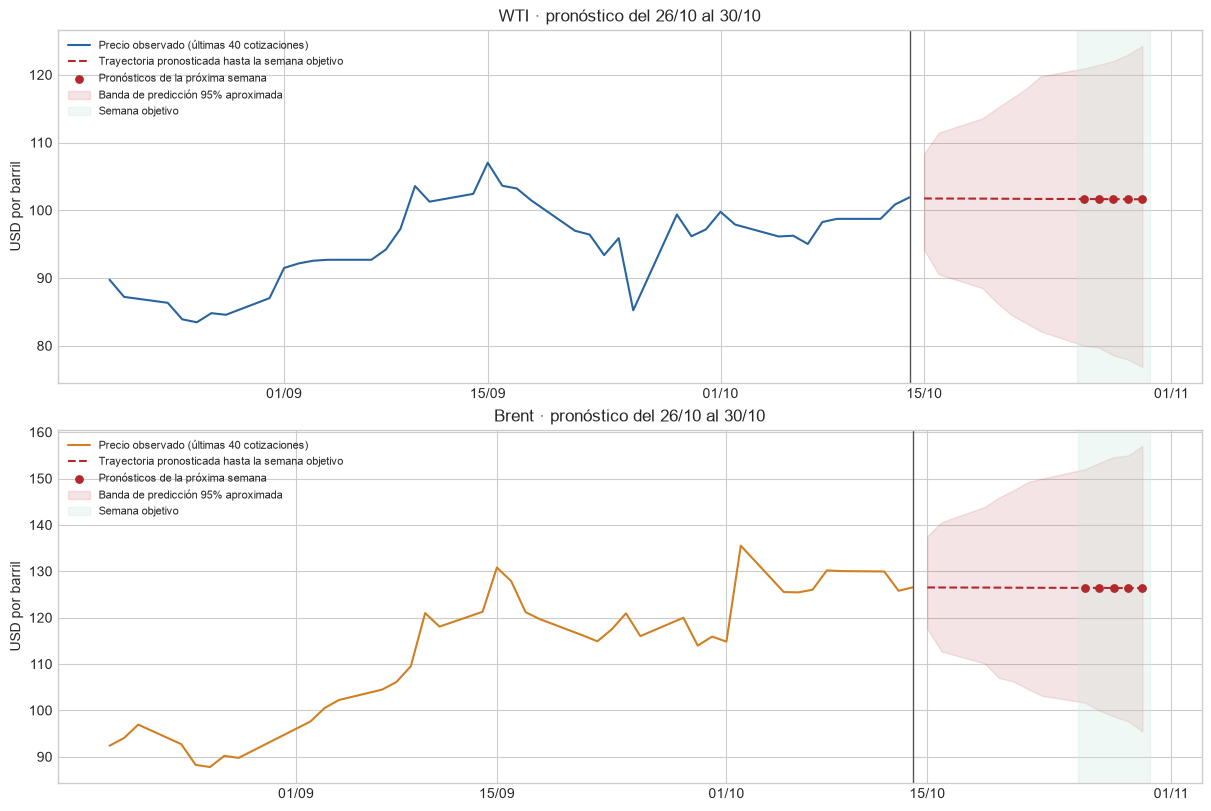

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)
for ax, (crudo, serie) in zip(axes, series_periodo_2.items()):
    futuro = trayectorias_pronostico[crudo]
    objetivo = futuro.loc[futuro["Fecha"].isin(fechas_objetivo)]
    ax.plot(serie.tail(40).index, serie.tail(40), color=COLORES[crudo],
            label="Precio observado (últimas 40 cotizaciones)")
    ax.plot(futuro["Fecha"], futuro["Holt (USD/barril)"], color="#B3282D",
            linestyle="--", label="Trayectoria pronosticada hasta la semana objetivo")
    ax.scatter(objetivo["Fecha"], objetivo["Holt (USD/barril)"], color="#B3282D", s=28,
               zorder=4, label="Pronósticos de la próxima semana")
    ax.fill_between(
        futuro["Fecha"], futuro["Inferior 95% aprox."], futuro["Superior 95% aprox."],
        color="#B3282D", alpha=0.12, label="Banda de predicción 95% aproximada",
    )
    ax.axvline(serie.index[-1], color="#555555", linewidth=1)
    ax.axvspan(inicio_semana - pd.Timedelta(hours=12), fin_semana + pd.Timedelta(hours=12),
               color="#CFE8DE", alpha=0.3, label="Semana objetivo")
    ax.set(title=f"{crudo} · pronóstico del {inicio_semana:%d/%m} al {fin_semana:%d/%m}",
           ylabel="USD por barril")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.legend(loc="best", fontsize=8)
plt.show()

## 8. Residuos y límites de la interpretación

Los residuos son diferencias entre precios observados y ajustes de un paso dentro del entrenamiento. Sirven para explorar lo que el modelo no explica; **no reemplazan los errores de la validación temporal**.

La autocorrelación de los residuos puede mostrar dependencia pendiente de modelar. Las bandas del gráfico son referencias puntuales aproximadas; no certifican que los errores sean independientes ni que los intervalos futuros estén calibrados.

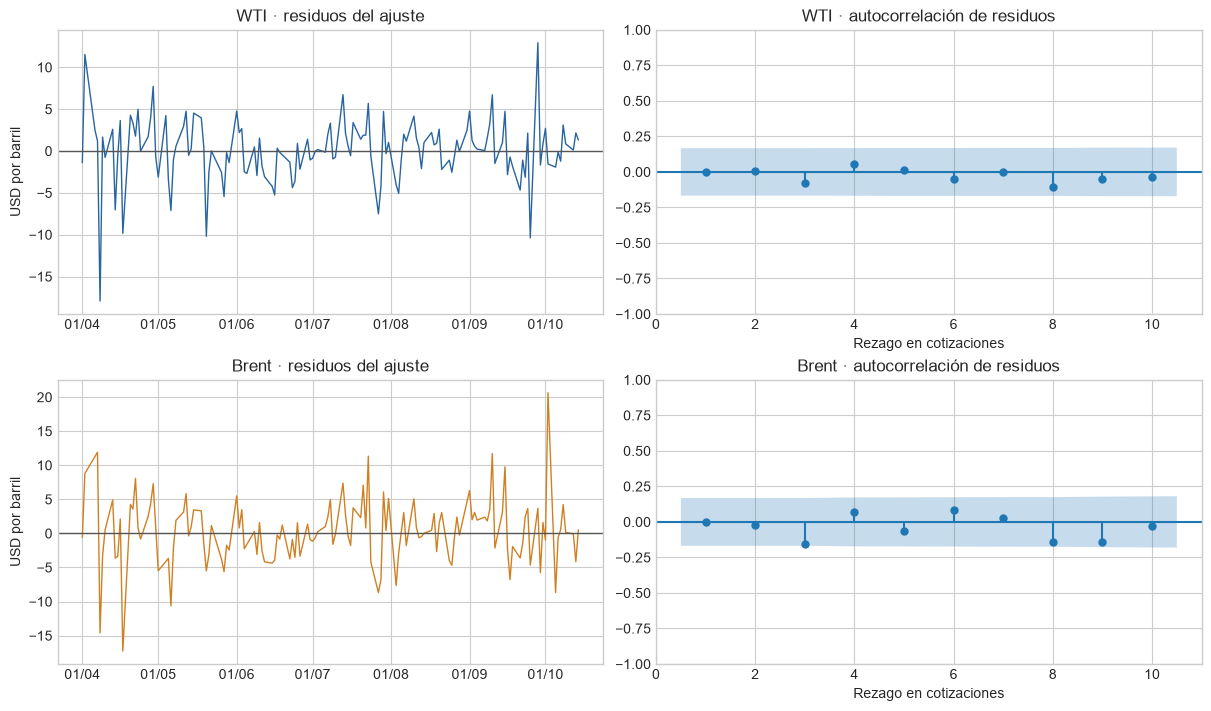

,Crudo,Media residual,Desvío residual,Autocorrelación de rezago 1
0,WTI,0.106,3.850,-0.000
1,Brent,0.255,4.843,-0.001


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
filas_residuos = []
for fila, (crudo, serie) in enumerate(series_periodo_2.items()):
    resid = pd.Series(ajustes_finales[crudo].resid, index=serie.index)
    axes[fila, 0].plot(resid.index, resid, color=COLORES[crudo], linewidth=1)
    axes[fila, 0].axhline(0, color="#555555", linewidth=1)
    axes[fila, 0].set(title=f"{crudo} · residuos del ajuste", ylabel="USD por barril")
    axes[fila, 0].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    plot_acf(resid.to_numpy(), lags=10, zero=False, ax=axes[fila, 1],
             title=f"{crudo} · autocorrelación de residuos")
    axes[fila, 1].set_xlabel("Rezago en cotizaciones")
    filas_residuos.append({
        "Crudo": crudo, "Media residual": resid.mean(),
        "Desvío residual": resid.std(ddof=1), "Autocorrelación de rezago 1": resid.autocorr(1),
    })
plt.show()
display(pd.DataFrame(filas_residuos).style.format(precision=3))

## 9. Lectura para el TP

El método usa precios observados durante el período de guerra definido por el grupo, pero no contiene variables que describan decisiones políticas o eventos bélicos. Su resultado depende de que la dinámica reciente conserve cierta continuidad.

Al volver a ejecutar todas las celdas, se recalculan la próxima semana, los datos disponibles, la validación y los pronósticos. Si se utiliza CSV, es necesario actualizar esa copia para incorporar nuevas publicaciones. La fecha impresa en las salidas permite saber a qué ejecución corresponde cada resultado.

No se declara a Holt superior a ARIMA: todavía falta implementar y evaluar ese segundo modelo bajo **los mismos cortes, horizontes y métricas**.

In [12]:
for crudo, serie in series_periodo_2.items():
    semana = pronostico_semana.loc[pronostico_semana["Crudo"].eq(crudo)]
    promedio = semana["Holt (USD/barril)"].mean()
    display(Markdown(
        f"**{crudo}.** Con {len(serie)} cotizaciones desde {serie.index.min():%d/%m/%Y} "
        f"hasta {serie.index.max():%d/%m/%Y}, Holt estima un promedio de los cinco "
        f"pronósticos de **{promedio:.2f} USD/barril** para la semana objetivo. "
        f"El último precio observado fue **{serie.iloc[-1]:.2f} USD/barril**. "
        "El promedio resume las predicciones diarias; no es un precio semanal ya observado."
    ))

display(pd.DataFrame({
    "Componente": ["Python", "pandas", "NumPy", "statsmodels", "Fuente", "Referencia Argentina"],
    "Valor": [platform.python_version(), pd.__version__, np.__version__,
              statsmodels.__version__, origen, fecha_referencia.strftime("%Y-%m-%d")],
}))

**WTI.** Con 138 cotizaciones desde 01/04/2026 hasta 14/10/2026, Holt estima un promedio de los cinco pronósticos de **101.64 USD/barril** para la semana objetivo. El último precio observado fue **101.91 USD/barril**. El promedio resume las predicciones diarias; no es un precio semanal ya observado.

**Brent.** Con 136 cotizaciones desde 01/04/2026 hasta 14/10/2026, Holt estima un promedio de los cinco pronósticos de **126.39 USD/barril** para la semana objetivo. El último precio observado fue **126.55 USD/barril**. El promedio resume las predicciones diarias; no es un precio semanal ya observado.

,Componente,Valor
0,Python,3.11.9
1,pandas,2.3.3
2,NumPy,2.4.6
3,statsmodels,0.15.0
4,Fuente,API EIA · precios spot diarios
5,Referencia Argentina,2026-10-20


## Fuentes

- [EIA Open Data: precios spot del petróleo](https://www.eia.gov/opendata/browser/petroleum/pri/spt).
- [Hyndman y Athanasopoulos: métodos con tendencia](https://otexts.com/fpp3/holt.html).
- [Hyndman y Athanasopoulos: validación temporal](https://otexts.com/fpp3/tscv.html).
- [statsmodels: suavizamiento exponencial](https://www.statsmodels.org/stable/examples/notebooks/generated/exponential_smoothing.html).
- [statsmodels: simulación de trayectorias de Holt](https://www.statsmodels.org/stable/generated/statsmodels.tsa.holtwinters.HoltWintersResults.simulate.html).

La limpieza sigue los criterios del notebook local `periodo_2_wti_brent.ipynb`. Este archivo se puede ejecutar desde la raíz del proyecto o desde `notebooks/`.